In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

In [2]:
headers = {"User-Agent": "Mozilla/5.0"}
url = "https://www.worldometers.info/world-population/population-by-country/"

response = requests.get(url, headers=headers)
print(response.status_code)

soup = BeautifulSoup(response.text, "html.parser")
table = soup.find("table")
rows = table.find_all("tr")[1:]

data = []

for row in rows:
    cols = row.find_all("td")
    if len(cols) < 11:
        continue

    country = cols[1].text.strip()
    population = cols[2].text.strip()
    yearly_change = cols[3].text.strip()
    net_change = cols[4].text.strip()
    density = cols[5].text.strip()
    land_area = cols[6].text.strip()
    migrants = cols[7].text.strip()
    fert_rate = cols[8].text.strip()
    median_age = cols[9].text.strip()
    urban_pop = cols[10].text.strip()
    world_share = cols[11].text.strip()

    data.append([
        country, population, yearly_change, net_change, density,
        land_area, migrants, fert_rate, median_age, urban_pop, world_share
    ])

df = pd.DataFrame(data, columns=[
    "Country", "Population_2026", "Yearly_Change_%", "Net_Change",
    "Density_P_Km2", "Land_Area_Km2", "Migrants_Net", "Fert_Rate",
    "Median_Age", "Urban_Pop_%", "World_Share_%"
])

df.to_csv("population.csv", index=False)
df.head()

200


,Country,Population_2026,Yearly_Change_%,Net_Change,Density_P_Km2,Land_Area_Km2,Migrants_Net,Fert_Rate,Median_Age,Urban_Pop_%,World_Share_%
0,India,"1,476,625,576",0.87%,"12,760,051",497,"2,973,190","â440,456",1.93,29.2,37.6%,17.8%
1,China,"1,412,914,089",â0.22%,"â3,182,005",150,"9,388,211","â232,107",1.03,40.6,68.7%,17%
2,United States,"349,035,494",0.51%,"1,759,687",38,"9,147,420","1,177,848",1.63,38.7,83.1%,4.2%
3,Indonesia,"287,886,782",0.76%,"2,165,546",159,"1,811,570","â39,472",2.08,30.7,60.3%,3.5%
4,Pakistan,"259,299,791",1.6%,"4,080,237",336,"770,880","â1,144,738",3.44,20.8,34.7%,3.1%


In [3]:
import numpy as np

df = pd.read_csv("population.csv")

for col in ["Population_2026", "Net_Change", "Density_P_Km2", "Land_Area_Km2", "Migrants_Net"]:
    df[col] = df[col].astype(str).str.replace(",", "", regex=False)
    df[col] = df[col].replace("–", np.nan)
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in ["Yearly_Change_%", "Fert_Rate", "Median_Age", "Urban_Pop_%", "World_Share_%"]:
    df[col] = df[col].astype(str).str.replace("%", "", regex=False).str.replace("−", "-", regex=False)
    df[col] = df[col].replace("–", np.nan)
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["log_Population"] = np.log(df["Population_2026"])

df.to_csv("population_cleaned.csv", index=False)
df.head()

,Country,Population_2026,Yearly_Change_%,Net_Change,Density_P_Km2,Land_Area_Km2,Migrants_Net,Fert_Rate,Median_Age,Urban_Pop_%,World_Share_%,log_Population
0,India,1476625576,0.87,12760051.0,497,2973190,NaN,1.93,29.2,37.6,17.8,21.113025
1,China,1412914089,NaN,NaN,150,9388211,NaN,1.03,40.6,68.7,17.0,21.068920
2,United States,349035494,0.51,1759687.0,38,9147420,1177848.0,1.63,38.7,83.1,4.2,19.670684
3,Indonesia,287886782,0.76,2165546.0,159,1811570,NaN,2.08,30.7,60.3,3.5,19.478078
4,Pakistan,259299791,1.60,4080237.0,336,770880,NaN,3.44,20.8,34.7,3.1,19.373495


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("population_cleaned.csv")
print("Dataset loaded successfully")
df.head()

Dataset loaded successfully


,Country,Population_2026,Yearly_Change_%,Net_Change,Density_P_Km2,Land_Area_Km2,Migrants_Net,Fert_Rate,Median_Age,Urban_Pop_%,World_Share_%,log_Population
0,India,1476625576,0.87,12760051.0,497,2973190,NaN,1.93,29.2,37.6,17.8,21.113025
1,China,1412914089,NaN,NaN,150,9388211,NaN,1.03,40.6,68.7,17.0,21.068920
2,United States,349035494,0.51,1759687.0,38,9147420,1177848.0,1.63,38.7,83.1,4.2,19.670684
3,Indonesia,287886782,0.76,2165546.0,159,1811570,NaN,2.08,30.7,60.3,3.5,19.478078
4,Pakistan,259299791,1.60,4080237.0,336,770880,NaN,3.44,20.8,34.7,3.1,19.373495


In [5]:
df.shape

(234, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Country          234 non-null    object 
 1   Population_2026  234 non-null    int64  
 2   Yearly_Change_%  172 non-null    float64
 3   Net_Change       172 non-null    float64
 4   Density_P_Km2    234 non-null    int64  
 5   Land_Area_Km2    234 non-null    int64  
 6   Migrants_Net     100 non-null    float64
 7   Fert_Rate        234 non-null    float64
 8   Median_Age       234 non-null    float64
 9   Urban_Pop_%      210 non-null    float64
 10  World_Share_%    234 non-null    float64
 11  log_Population   234 non-null    float64
dtypes: float64(8), int64(3), object(1)
memory usage: 22.1+ KB


In [7]:
print("Mean:")
print(df.mean(numeric_only=True))

print("Median:")
print(df.median(numeric_only=True))

print("Mode:")
print(df.mode(numeric_only=True).iloc[0])

print("Variance:")
print(df.var(numeric_only=True))

print("Standard Deviation:")
print(df.std(numeric_only=True))

print("Quartiles:")
print(df[["Population_2026", "log_Population"]].quantile([0.25, 0.5, 0.75]))

Mean:
Population_2026    3.546514e+07
Yearly_Change_%    1.357384e+00
Net_Change         4.391687e+05
Density_P_Km2      4.889274e+02
Land_Area_Km2      5.559568e+05
Migrants_Net       4.917102e+04
Fert_Rate          2.282735e+00
Median_Age         3.221838e+01
Urban_Pop_%        6.113476e+01
World_Share_%      4.269144e-01
log_Population     1.491829e+01
dtype: float64
Median:
Population_2026    5.776466e+06
Yearly_Change_%    1.180000e+00
Net_Change         8.406500e+04
Density_P_Km2      1.000000e+02
Land_Area_Km2      7.972000e+04
Migrants_Net       6.621000e+03
Fert_Rate          1.925000e+00
Median_Age         3.335000e+01
Urban_Pop_%        6.240000e+01
World_Share_%      7.000000e-02
log_Population     1.556921e+01
dtype: float64
Mode:
Population_2026    506.000000
Yearly_Change_%      0.440000
Net_Change         524.000000
Density_P_Km2        4.000000
Land_Area_Km2      460.000000
Migrants_Net         0.000000
Fert_Rate            1.470000
Median_Age          39.100000
Urban_

In [8]:
df.describe()

,Population_2026,Yearly_Change_%,Net_Change,Density_P_Km2,Land_Area_Km2,Migrants_Net,Fert_Rate,Median_Age,Urban_Pop_%,World_Share_%,log_Population
count,2.340000e+02,172.000000,1.720000e+02,234.000000,2.340000e+02,1.000000e+02,234.000000,234.000000,210.000000,234.000000,234.000000
mean,3.546514e+07,1.357384,4.391687e+05,488.927350,5.559568e+05,4.917102e+04,2.282735,32.218376,61.134762,0.426914,14.918285
std,1.394742e+08,0.887911,1.186648e+06,2402.936254,1.691024e+06,1.355400e+05,1.103612,9.907224,22.521851,1.679496,2.832037
min,5.060000e+02,0.020000,1.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.700000,14.600000,11.700000,0.000006,6.226537
25%,4.389268e+05,0.600000,5.500500e+03,39.250000,2.650000e+03,4.755000e+02,1.470000,23.125000,43.250000,0.005325,12.991289
50%,5.776466e+06,1.180000,8.406500e+04,100.000000,7.972000e+04,6.621000e+03,1.925000,33.350000,62.400000,0.070000,15.569213
75%,2.428835e+07,2.022500,3.869662e+05,260.250000,4.070800e+05,3.254050e+04,2.882500,40.275000,80.500000,0.295000,17.005253
max,1.476626e+09,3.370000,1.276005e+07,25562.000000,1.637687e+07,1.177848e+06,5.830000,56.200000,99.600000,17.800000,21.113025


In [9]:
mean_pop = df["Population_2026"].mean()
median_pop = df["Population_2026"].median()
std_pop = df["Population_2026"].std()

print(f"Mean Population: {mean_pop:,.0f}")
print(f"Median Population: {median_pop:,.0f}")
print(f"Std Dev: {std_pop:,.0f}")
print(f"Mean is {mean_pop/median_pop:.1f}x the median — strong right-skew")

Mean Population: 35,465,140
Median Population: 5,776,466
Std Dev: 139,474,153
Mean is 6.1x the median — strong right-skew


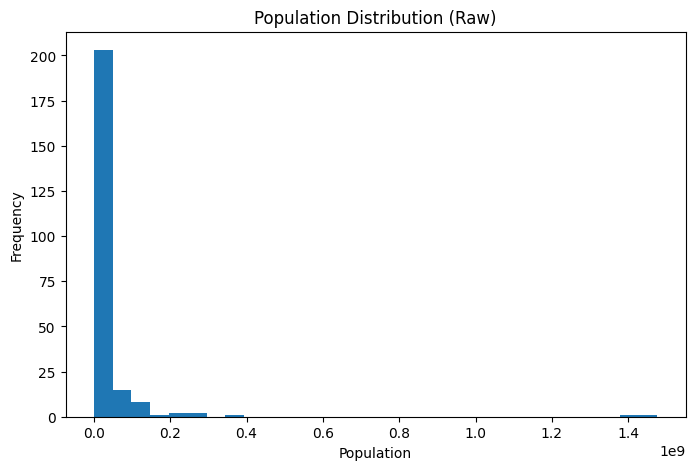

In [10]:
plt.figure(figsize=(8,5))
plt.hist(df["Population_2026"].dropna(), bins=30)
plt.title("Population Distribution (Raw)")
plt.xlabel("Population")
plt.ylabel("Frequency")
plt.show()

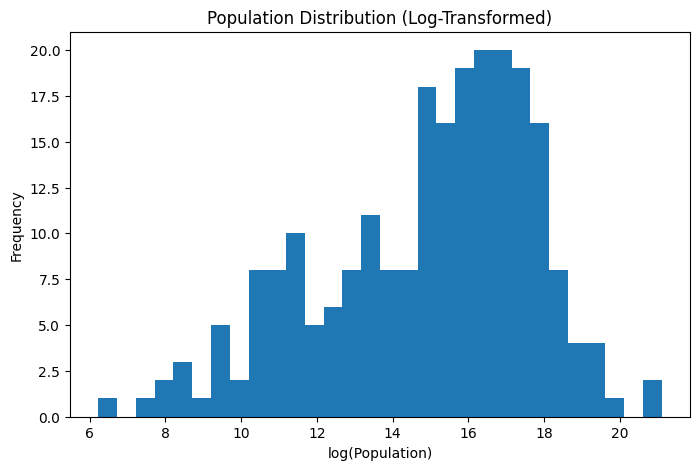

In [11]:
plt.figure(figsize=(8,5))
plt.hist(df["log_Population"].dropna(), bins=30)
plt.title("Population Distribution (Log-Transformed)")
plt.xlabel("log(Population)")
plt.ylabel("Frequency")
plt.show()

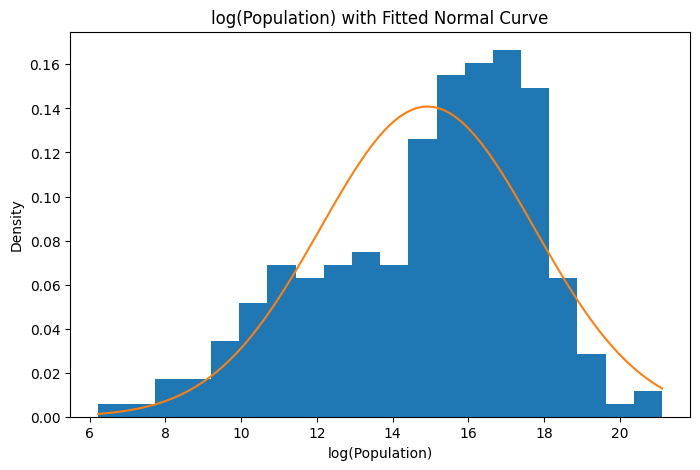

In [12]:
mean = df["log_Population"].mean()
std = df["log_Population"].std()

x = np.linspace(
    df["log_Population"].min(),
    df["log_Population"].max(),
    100
)

normal = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(
    -0.5 * ((x - mean) / std) ** 2
)

plt.figure(figsize=(8,5))
plt.hist(
    df["log_Population"],
    bins=20,
    density=True
)

plt.plot(x, normal)

plt.title("log(Population) with Fitted Normal Curve")
plt.xlabel("log(Population)")
plt.ylabel("Density")
plt.show()

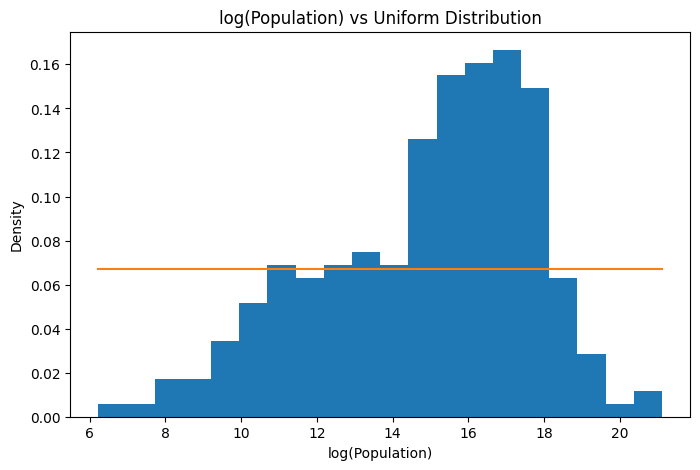

In [13]:
minimum = df["log_Population"].min()
maximum = df["log_Population"].max()

uniform = np.ones(100) / (maximum - minimum)

plt.figure(figsize=(8,5))
plt.hist(
    df["log_Population"],
    bins=20,
    density=True
)

plt.plot(x, uniform)

plt.title("log(Population) vs Uniform Distribution")
plt.xlabel("log(Population)")
plt.ylabel("Density")
plt.show()

In [14]:
np.random.seed(42)

population = df["log_Population"].dropna().values

population_mean = np.mean(population)
population_std = np.std(population)

print(f'Population mean (log): {population_mean}')
print(f'Population std (log): {population_std}')

Population mean (log): 14.918285250010095
Population std (log): 2.825979232222622


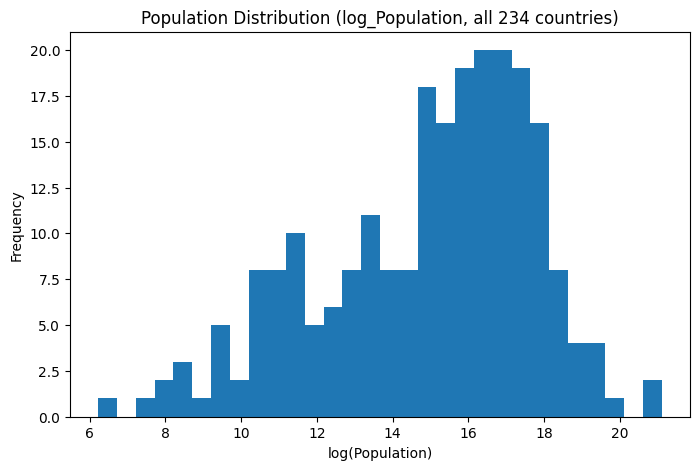

In [15]:
plt.figure(figsize=(8,5))
plt.hist(population, bins=30)
plt.title("Population Distribution (log_Population, all 234 countries)")
plt.xlabel("log(Population)")
plt.ylabel("Frequency")
plt.show()

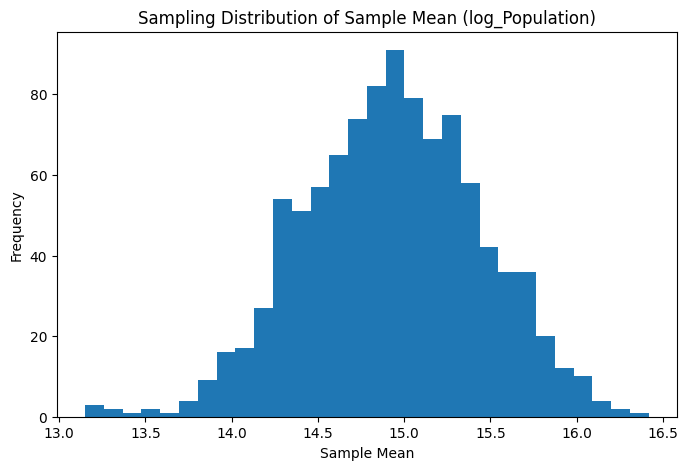

In [16]:
sample_size = 30
number_of_samples = 1000

sample_means = []

for _ in range(number_of_samples):
    sample = np.random.choice(population, size=sample_size)
    sample_mean = np.mean(sample)
    sample_means.append(sample_mean)

plt.figure(figsize=(8,5))
plt.hist(sample_means, bins=30)
plt.title("Sampling Distribution of Sample Mean (log_Population)")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.show()

In [17]:
estimated_mean = np.mean(sample_means)

print("Point Estimate of population mean:", estimated_mean)
print("Actual population mean:", population_mean)
print("Difference:", abs(population_mean - estimated_mean))

standard_error = population_std / np.sqrt(sample_size)
print("Standard Error of Mean:", standard_error)

Point Estimate of population mean: 14.930107276919635
Actual population mean: 14.918285250010095
Difference: 0.011822026909539929
Standard Error of Mean: 0.5159508575098201


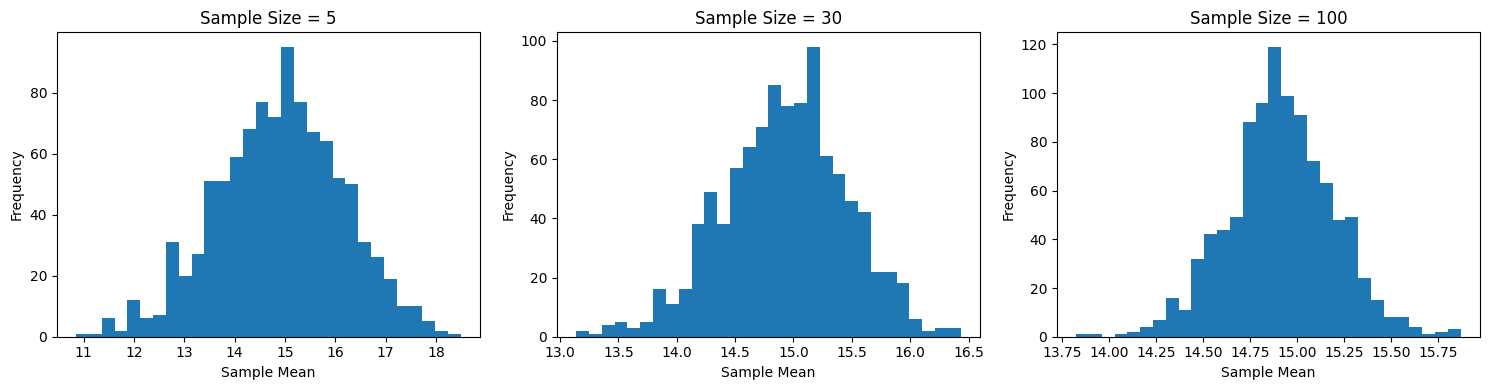

In [18]:
sample_sizes = [5, 30, 100]

plt.figure(figsize=(15,4))

for i, size in enumerate(sample_sizes):
    means = [np.mean(np.random.choice(population, size=size)) for _ in range(1000)]
    plt.subplot(1, 3, i+1)
    plt.hist(means, bins=30)
    plt.title(f"Sample Size = {size}")
    plt.xlabel("Sample Mean")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [19]:
from sklearn.model_selection import train_test_split

feature_cols = ["Density_P_Km2", "Land_Area_Km2", "Fert_Rate", "Median_Age", "Urban_Pop_%", "Migrants_Net", "Yearly_Change_%"]

model_df = df[feature_cols + ["log_Population"]].dropna()

X = model_df[feature_cols]
y = model_df["log_Population"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (57, 7)
Test shape: (15, 7)


In [20]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Coefficients:")
for col, coef in zip(feature_cols, model.coef_):
    print(f"  {col}: {coef:.4f}")

print("Intercept:", model.intercept_)

Coefficients:
  Density_P_Km2: -0.0004
  Land_Area_Km2: 0.0000
  Fert_Rate: -0.5098
  Median_Age: -0.2601
  Urban_Pop_%: 0.0346
  Migrants_Net: 0.0000
  Yearly_Change_%: -0.4921
Intercept: 21.85961289017824


In [21]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 3.088444163206358
MSE: 21.108444495695252
RMSE: 4.594392723276413
R2 Score: -3.3374107510462103


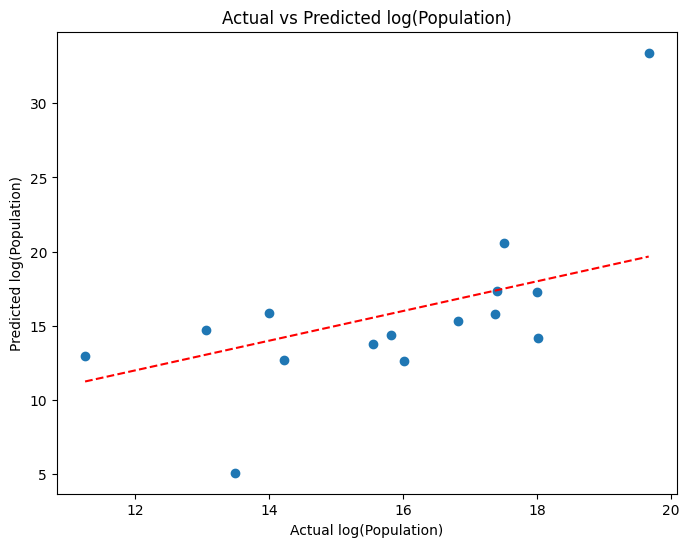

In [22]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual log(Population)")
plt.ylabel("Predicted log(Population)")
plt.title("Actual vs Predicted log(Population)")
plt.show()

In [23]:
predicted_population = np.exp(y_pred)
actual_population = np.exp(y_test)

comparison = pd.DataFrame({
    "Actual_Population": actual_population.values,
    "Predicted_Population": predicted_population
})

comparison.head(10)

,Actual_Population,Predicted_Population
0,6.674640e+07,1.411151e+06
1,7.719600e+04,4.430364e+05
2,2.030591e+07,4.410777e+06
3,3.490355e+08,3.198109e+14
4,9.007798e+06,3.085706e+05
5,7.231880e+05,1.655674e+02
6,3.638511e+07,3.330531e+07
7,5.652989e+06,9.330823e+05
8,3.492215e+07,7.462819e+06
9,4.697750e+05,2.550555e+06


In [24]:
from scipy import stats
import numpy as np

population = df["log_Population"].dropna()

In [25]:
# 95% Confidence Interval
n = len(population)
sample_mean = population.mean()
standard_error = population.std(ddof=1) / np.sqrt(n)

ci = stats.t.interval(
    0.95,
    df=n - 1,
    loc=sample_mean,
    scale=standard_error
)

print("Sample Mean:", sample_mean)
print("Standard Error:", standard_error)
print("95% Confidence Interval:", ci)


Sample Mean: 14.918285250010095
Standard Error: 0.18513605507359365
95% Confidence Interval: (np.float64(14.553530638821053), np.float64(15.283039861199137))


In [26]:
# One-Sample T-Test
hypothesized_mean = np.log(10000000)

t_stat, p_value = stats.ttest_1samp(
    population,
    hypothesized_mean
)

print("\nOne-Sample T-Test")
print("T-Statistic:", t_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")



One-Sample T-Test
T-Statistic: -6.480695510505974
P-Value: 5.381972495937357e-10
Reject the null hypothesis


Covariance Matrix:
                 Density_P_Km2  Land_Area_Km2     Fert_Rate     Median_Age  \
Density_P_Km2     8.214752e+06  -3.697498e+08   -527.477934    3448.495775   
Land_Area_Km2    -3.697498e+08   3.130528e+12 -58345.450806  761615.098592   
Fert_Rate        -5.274779e+02  -5.834545e+04      0.866830      -6.368856   
Median_Age        3.448496e+03   7.616151e+05     -6.368856      59.941338   
Urban_Pop_%       1.146821e+04   5.401263e+06    -10.420309      78.114894   
Migrants_Net     -2.459069e+07   1.852264e+11  -7273.704067   84474.958803   
Yearly_Change_%  -3.488102e+02  -8.555128e+04      0.593360      -4.914676   
log_Population   -8.593033e+02   1.918948e+06      0.616737      -6.937130   

                  Urban_Pop_%  Migrants_Net  Yearly_Change_%  log_Population  
Density_P_Km2    1.146821e+04 -2.459069e+07      -348.810188   -8.593033e+02  
Land_Area_Km2    5.401263e+06  1.852264e+11    -85551.277543    1.918948e+06  
Fert_Rate       -1.042031e+01 -7.273704e+

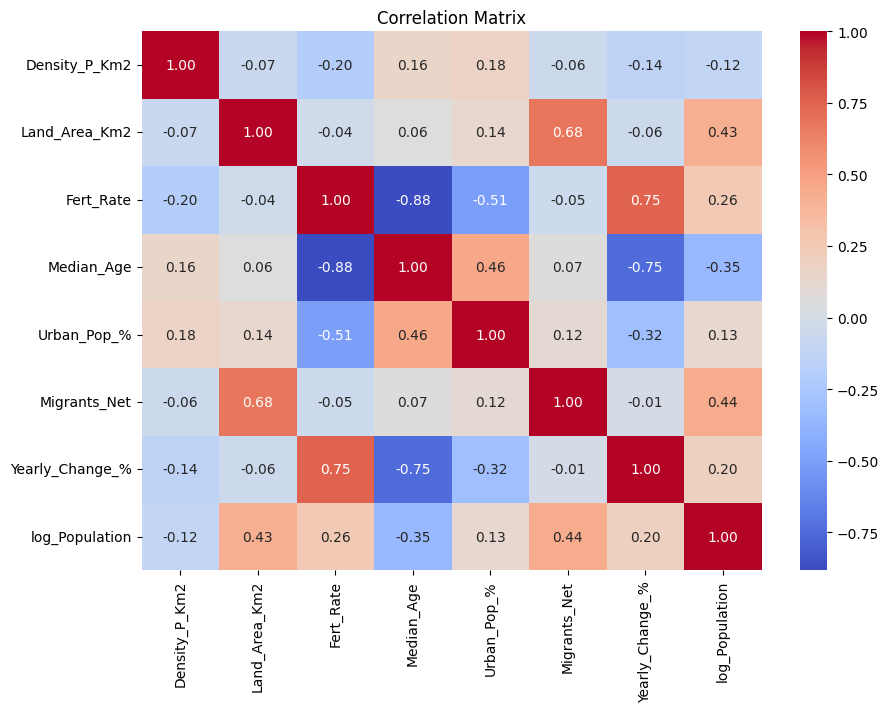


Feature: Density_P_Km2
Pearson Correlation: -0.11483143140442675
Pearson P-Value: 0.07960547563634854
Spearman Correlation: -0.10233569030265349
Spearman P-Value: 0.11848756089515879

Feature: Land_Area_Km2
Pearson Correlation: 0.36759297066610314
Pearson P-Value: 6.742288012757666e-09
Spearman Correlation: 0.8575808399189366
Spearman P-Value: 6.261242131835863e-69

Feature: Fert_Rate
Pearson Correlation: 0.22317186282158874
Pearson P-Value: 0.0005837213793609994
Spearman Correlation: 0.19580900996739123
Spearman P-Value: 0.0026259405998393624

Feature: Median_Age
Pearson Correlation: -0.2948695133851644
Pearson P-Value: 4.4554032214168e-06
Spearman Correlation: -0.2729366026669014
Spearman P-Value: 2.3015940904339602e-05

Feature: Urban_Pop_%
Pearson Correlation: -0.0012340592263552722
Pearson P-Value: 0.985817165387489
Spearman Correlation: -0.044351262205807665
Spearman P-Value: 0.5226997940972867

Feature: Migrants_Net
Pearson Correlation: 0.4140444242774677
Pearson P-Value: 1.850

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

correlation_cols = [
    "Density_P_Km2",
    "Land_Area_Km2",
    "Fert_Rate",
    "Median_Age",
    "Urban_Pop_%",
    "Migrants_Net",
    "Yearly_Change_%",
    "log_Population"
]

corr_df = df[correlation_cols].dropna()

print("Covariance Matrix:")
print(corr_df.cov())

print("\nPearson Correlation Matrix:")
print(corr_df.corr())

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix")
plt.show()

for col in correlation_cols:
    if col == "log_Population":
        continue

    pair_df = df[[col, "log_Population"]].dropna()

    pearson_r, pearson_p = pearsonr(
        pair_df[col],
        pair_df["log_Population"]
    )

    spearman_rho, spearman_p = spearmanr(
        pair_df[col],
        pair_df["log_Population"]
    )

    print("\nFeature:", col)
    print("Pearson Correlation:", pearson_r)
    print("Pearson P-Value:", pearson_p)
    print("Spearman Correlation:", spearman_rho)
    print("Spearman P-Value:", spearman_p)

In [29]:
feature_cols = [
    "Density_P_Km2",
    "Land_Area_Km2",
    "Fert_Rate",
    "Median_Age",
    "Urban_Pop_%",
    "Migrants_Net",
    "Yearly_Change_%"
]

model_df = df[feature_cols + ["log_Population"]].copy()

# Fill missing numerical values using median
for col in feature_cols:
    model_df[col] = model_df[col].fillna(
        model_df[col].median()
    )

# Remove rows only if target is missing
model_df = model_df.dropna(
    subset=["log_Population"]
)

print("Regression dataset shape:", model_df.shape)
print(model_df.isnull().sum())

Regression dataset shape: (234, 8)
Density_P_Km2      0
Land_Area_Km2      0
Fert_Rate          0
Median_Age         0
Urban_Pop_%        0
Migrants_Net       0
Yearly_Change_%    0
log_Population     0
dtype: int64


In [30]:
from sklearn.model_selection import train_test_split

X = model_df[feature_cols]
y = model_df["log_Population"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (187, 7)
Test shape: (47, 7)


In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [32]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Linear Regression
linear_model = LinearRegression()

linear_model.fit(
    X_train_scaled,
    y_train
)

linear_pred = linear_model.predict(
    X_test_scaled
)


# Ridge Regression
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(
    X_train_scaled,
    y_train
)

ridge_pred = ridge_model.predict(
    X_test_scaled
)


# Lasso Regression
lasso_model = Lasso(alpha=0.1)

lasso_model.fit(
    X_train_scaled,
    y_train
)

lasso_pred = lasso_model.predict(
    X_test_scaled
)


# Decision Tree
tree_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

tree_model.fit(
    X_train,
    y_train
)

tree_pred = tree_model.predict(
    X_test
)


# Random Forest
forest_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

forest_model.fit(
    X_train,
    y_train
)

forest_pred = forest_model.predict(
    X_test
)

In [35]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions = {
    "Linear Regression": linear_pred,
    "Ridge Regression": ridge_pred,
    "Lasso Regression": lasso_pred,
    "Decision Tree": tree_pred,
    "Random Forest": forest_pred
}

results = []

for model_name, pred in predictions.items():

    mae = mean_absolute_error(y_test, pred)

    mse = mean_squared_error(y_test, pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, pred)

    results.append([
        model_name,
        mae,
        mse,
        rmse,
        r2
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score"
    ]
)

print(results_df.round(4).to_string(index=False))

            Model    MAE    MSE   RMSE  R2 Score
Linear Regression 2.5259 8.2469 2.8717    0.0793
 Ridge Regression 2.5247 8.2256 2.8680    0.0817
 Lasso Regression 2.5125 8.0132 2.8308    0.1054
    Decision Tree 1.1268 2.4877 1.5772    0.7223
    Random Forest 0.6198 1.0019 1.0010    0.8881


In [36]:
best_model_name = results_df.loc[
    results_df["R2 Score"].idxmax(),
    "Model"
]

print("Best Model:", best_model_name)

Best Model: Random Forest


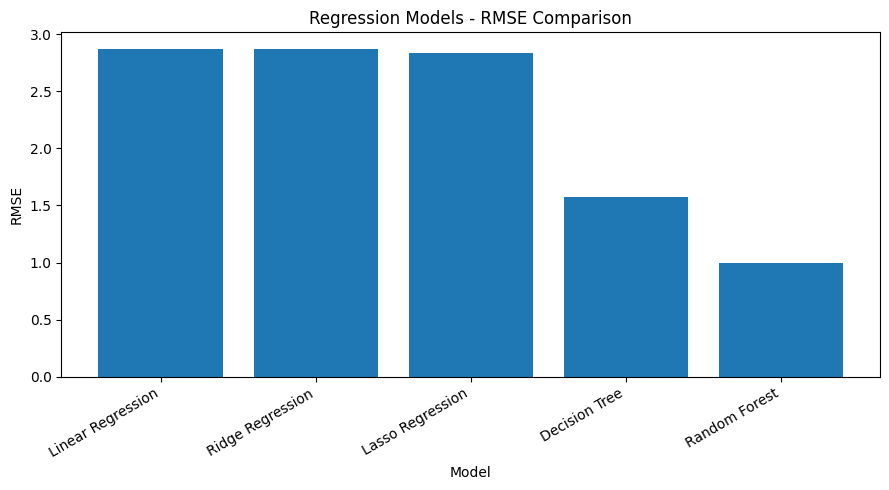

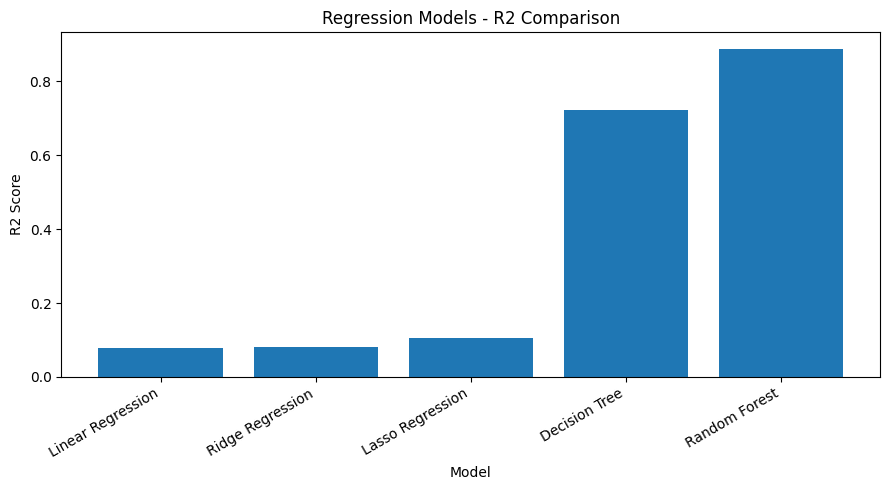

In [37]:
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("Regression Models - RMSE Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("Regression Models - R2 Comparison")
plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

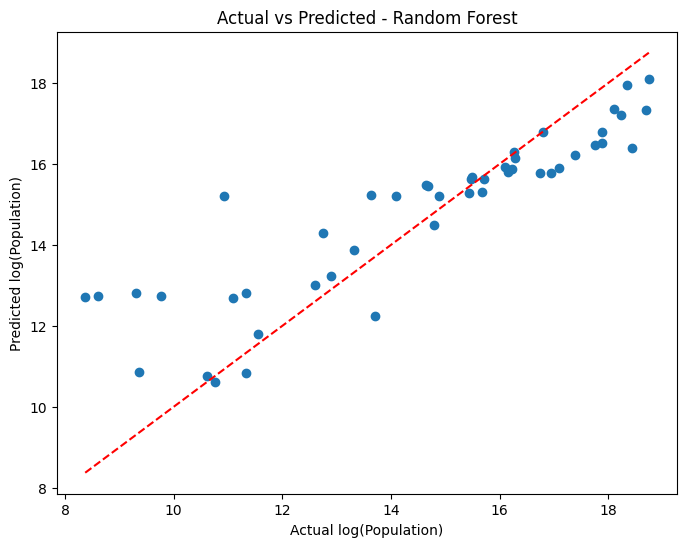

Best Model: Random Forest
Best RMSE: 1.0009555769320895
Best R2 Score: 0.8881493279957708


In [39]:
best_name = results_df.loc[results_df["R2 Score"].idxmax(), "Model"]
best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)

minimum = min(y_test.min(), best_predictions.min())
maximum = max(y_test.max(), best_predictions.max())

plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_predictions)
plt.plot([minimum, maximum], [minimum, maximum], "r--")
plt.xlabel("Actual log(Population)")
plt.ylabel("Predicted log(Population)")
plt.title("Actual vs Predicted - " + best_name)
plt.show()

print("Best Model:", best_name)
print("Best RMSE:", results_df.loc[results_df["Model"] == best_name, "RMSE"].iloc[0])
print("Best R2 Score:", results_df.loc[results_df["Model"] == best_name, "R2 Score"].iloc[0])

           Feature  Importance
1    Land_Area_Km2    0.656105
5     Migrants_Net    0.241641
0    Density_P_Km2    0.044309
2        Fert_Rate    0.023673
3       Median_Age    0.014472
4      Urban_Pop_%    0.010393
6  Yearly_Change_%    0.009408


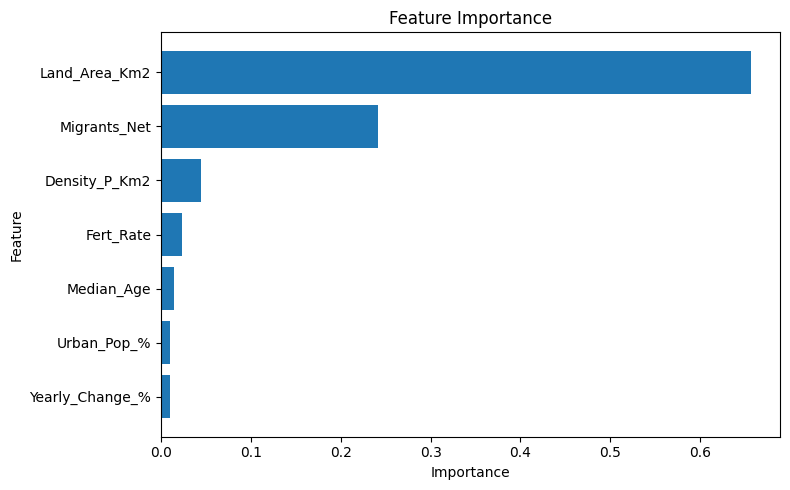

In [40]:
if best_name in ["Decision Tree", "Random Forest"]:
    importance_df = pd.DataFrame({
        "Feature": feature_cols,
        "Importance": best_model.feature_importances_
    }).sort_values(
        by="Importance",
        ascending=False
    )

    print(importance_df)

    plt.figure(figsize=(8, 5))
    plt.barh(
        importance_df["Feature"],
        importance_df["Importance"]
    )
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.title("Feature Importance")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

In [43]:
# Convert log population back to actual population
actual_population = np.exp(y_test)
predicted_population = np.exp(best_predictions)

# Create comparison table
comparison_df = pd.DataFrame({
    "Actual_Population": actual_population,
    "Predicted_Population": predicted_population
})

# Calculate absolute error
comparison_df["Absolute_Error"] = abs(
    comparison_df["Actual_Population"] -
    comparison_df["Predicted_Population"]
)

# Reset index for a clean table
comparison_df = comparison_df.reset_index(drop=True)

print("Best Model:", best_name)
print("Best RMSE:", results_df.iloc[0]["RMSE"])
print("Best R2 Score:", results_df.iloc[0]["R2 Score"])

print("\nActual vs Predicted Population:")
print(comparison_df.head(10).round(0).to_string(index=False))

Best Model: Random Forest
Best RMSE: 2.8717376675100574
Best R2 Score: 0.07934160031315407

Actual vs Predicted Population:
 Actual_Population  Predicted_Population  Absolute_Error
        18800605.0             7047360.0      11753245.0
           55629.0             4031195.0       3975566.0
          342564.0             1613194.0       1270630.0
       138902185.0            73438357.0      65463828.0
         5102773.0             4320504.0        782269.0
         6667659.0             6063035.0        604624.0
          103291.0              132826.0         29535.0
        10395362.0             7232233.0       3163129.0
           40368.0               46965.0          6597.0
       102177431.0            13194353.0      88983078.0


In [44]:
import joblib

joblib.dump(best_model, "best_population_model.pkl")
joblib.dump(feature_cols, "population_feature_columns.pkl")

loaded_model = joblib.load("best_population_model.pkl")
saved_features = joblib.load("population_feature_columns.pkl")

print("Model saved and loaded successfully")

Model saved and loaded successfully


In [45]:
new_country = X_test.iloc[[0]][saved_features]

predicted_log_population = loaded_model.predict(new_country)[0]
predicted_population = np.exp(predicted_log_population)

print("Input Features:")
print(new_country)

print("Predicted log Population:", predicted_log_population)
print("Predicted Population:", round(predicted_population))

Input Features:
    Density_P_Km2  Land_Area_Km2  Fert_Rate  Median_Age  Urban_Pop_%  \
69             82         230170       1.71        43.5         55.5   

    Migrants_Net  Yearly_Change_%  
69        6621.0             1.18  
Predicted log Population: 15.768163698774963
Predicted Population: 7047360


In [46]:
import gradio as gr
import joblib


joblib.dump(loaded_model, "population_model.joblib")
joblib.dump(saved_features, "population_features.joblib")


loaded_model = joblib.load("population_model.joblib")
saved_features = joblib.load("population_features.joblib")


In [47]:
def predict_population(
    Density_P_Km2,
    Land_Area_Km2,
    Fert_Rate,
    Median_Age,
    Urban_Pop_Percent,
    Migrants_Net,
    Yearly_Change_Percent
):
    new_country = pd.DataFrame([[
        Density_P_Km2,
        Land_Area_Km2,
        Fert_Rate,
        Median_Age,
        Urban_Pop_Percent,
        Migrants_Net,
        Yearly_Change_Percent
    ]], columns=saved_features)

    predicted_log_population = loaded_model.predict(new_country)[0]
    predicted_population = np.exp(predicted_log_population)

    return f"Predicted Population: {predicted_population:,.0f}"

In [50]:
import gradio as gr

def predict_population_ui(
    density, land_area, fertility, median_age,
    urban_pop, migrants, yearly_change
):
    result = predict_population(
        density, land_area, fertility, median_age,
        urban_pop, migrants, yearly_change
    )
    return result

custom_css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
}
#main-title {
    text-align: center;
    margin-bottom: 5px;
}
#subtitle {
    text-align: center;
    color: #64748b;
    margin-bottom: 25px;
}
.input-card, .output-card {
    border-radius: 14px !important;
    border: 1px solid #dbe4e8 !important;
    padding: 18px !important;
}
#predict-btn {
    background: #167d68 !important;
    color: white !important;
    border-radius: 10px !important;
}
#reset-btn {
    border-radius: 10px !important;
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="emerald",
        secondary_hue="slate",
        neutral_hue="slate"
    ),
    css=custom_css,
    title="World Population Predictor"
) as interface:

    gr.Markdown("# 🌍 World Population Predictor", elem_id="main-title")
    gr.Markdown(
        "Estimate a country's population using demographic and geographic data.",
        elem_id="subtitle"
    )

    with gr.Row():
        with gr.Column(scale=3):
            with gr.Group(elem_classes="input-card"):
                gr.Markdown("### 📊 Country Information")
                gr.Markdown("Enter the country's demographic details below.")

                with gr.Row():
                    density = gr.Number(
                        label="Population Density (people/km²)",
                        value=100,
                        minimum=0
                    )
                    land_area = gr.Number(
                        label="Land Area (km²)",
                        value=100000,
                        minimum=1
                    )

                with gr.Row():
                    fertility = gr.Number(
                        label="Fertility Rate",
                        value=2.0,
                        minimum=0
                    )
                    median_age = gr.Number(
                        label="Median Age",
                        value=30,
                        minimum=0,
                        maximum=100
                    )

                with gr.Row():
                    urban_pop = gr.Number(
                        label="Urban Population (%)",
                        value=50,
                        minimum=0,
                        maximum=100
                    )
                    migrants = gr.Number(
                        label="Net Migrants",
                        value=0
                    )

                yearly_change = gr.Number(
                    label="Yearly Population Change (%)",
                    value=1.0
                )

                with gr.Row():
                    predict_btn = gr.Button(
                        "🌍 Predict Population",
                        variant="primary",
                        elem_id="predict-btn"
                    )
                    reset_btn = gr.Button(
                        "↻ Reset Values",
                        elem_id="reset-btn"
                    )

        with gr.Column(scale=2):
            with gr.Group(elem_classes="output-card"):
                gr.Markdown("### 🎯 Prediction Result")
                result = gr.Textbox(
                    label="Estimated Population",
                    lines=3,
                    interactive=False,
                    placeholder="Your prediction will appear here."
                )

    input_components = [
        density, land_area, fertility, median_age,
        urban_pop, migrants, yearly_change
    ]

    predict_btn.click(
        fn=predict_population_ui,
        inputs=input_components,
        outputs=result
    )

    reset_btn.click(
        fn=lambda: [100, 100000, 2.0, 30, 50, 0, 1.0, ""],
        inputs=[],
        outputs=input_components + [result]
    )

interface.launch()

/tmp/ipykernel_1241/2202396090.py:42: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ffd8beaf7d96e27587.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
